<a href="https://colab.research.google.com/github/rifqiiiz/datascience-project/blob/main/03_model_design_baseline_ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03A - Model Design & Optimization: Baseline Model **[M + O]**

**Judul Proyek:** Prediksi Tingkat Kepadatan Lalu Lintas Perkotaan Menggunakan Algoritma Klasifikasi Machine Learning dan Multilayer Perceptron (PyTorch) Berbasis Data Sensor Jalan Raya  
**Nama / NIM:** Muhammad Rifqi Maulana / 244311018, , Vicky Rizkyanto / 244311030

**Program Studi:** D4 Teknologi Rekayasa Perangkat Lunak – Politeknik Negeri Madiun  
**Mata Kuliah:** Data Science (TRPL22406)  
**Model:** Model 1 – Baseline Model (*Logistic Regression*)

In [1]:
import os
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

sns.set_theme(style="whitegrid")

In [2]:
# 1. Memuat Data Hasil Preprocessing (Bebas Data Leakage dari Tahap L)
# Jika file .npz belum ada di sesi Colab, script otomatis menjalankan ulang pipeline preparation
if os.path.exists("../data/processed/traffic_splits.npz"):
    data = np.load("../data/processed/traffic_splits.npz")
    X_train, y_train = data["X_train"], data["y_train"]
    X_val, y_val = data["X_val"], data["y_val"]
    label_encoder = joblib.load("../models/label_encoder.joblib")
    class_names = label_encoder.classes_
else:
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
    from sklearn.compose import ColumnTransformer

    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00492/Metro_Interstate_Traffic_Volume.csv.gz"
    df = pd.read_csv(url, compression="gzip").drop_duplicates().reset_index(drop=True)
    df = df[df["temp"] > 200].reset_index(drop=True)
    df["holiday"] = df["holiday"].fillna("None")
    df["date_time"] = pd.to_datetime(df["date_time"])
    df["hour"] = df["date_time"].dt.hour
    df["day_of_week"] = df["date_time"].dt.dayofweek
    df["month"] = df["date_time"].dt.month
    df["is_weekend"] = df["day_of_week"].isin([5, 6]).astype(int)
    df["is_rush_hour"] = ((df["is_weekend"] == 0) & (df["hour"].isin([7, 8, 9, 16, 17, 18]))).astype(int)
    df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24.0)
    df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24.0)
    df["target_label"] = df["traffic_volume"].apply(lambda v: "Lancar" if v < 2500 else ("Padat" if v < 5000 else "Macet"))

    num_cols = ["temp", "rain_1h", "snow_1h", "clouds_all", "hour_sin", "hour_cos", "day_of_week", "month", "is_weekend", "is_rush_hour"]
    cat_cols = ["holiday", "weather_main"]
    X = df[num_cols + cat_cols]
    le = LabelEncoder()
    y = le.fit_transform(df["target_label"])
    class_names = le.classes_

    X_temp, _, y_temp, _ = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
    X_train_raw, X_val_raw, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)

    prep = ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)
    ])
    X_train = prep.fit_transform(X_train_raw)
    X_val = prep.transform(X_val_raw)

print(f"Shape X_train: {X_train.shape}, X_val: {X_val.shape}")
print(f"Kelas Target: {list(class_names)}")

Shape X_train: (28905, 33), X_val: (9636, 33)
Kelas Target: ['Lancar', 'Macet', 'Padat']


## 1. Model Design [M] — Hypothesis Space & Inductive Bias
- **Model Family:** Model Klasifikasi Linier (*Multinomial Logistic Regression*).
- **Hypothesis Space:** Himpunan seluruh hyperplane pemisah linier $h_W(x) = \text{softmax}(W x + b)$.
- **Inductive Bias:** Mengasumsikan log-odds tiap kelas kepadatan lalu lintas merupakan kombinasi linier dari fitur waktu dan cuaca, serta mengasumsikan batas keputusan antar-kelas dapat dipisahkan secara linier.

In [3]:
# 2. Training & Eksperimen Regularisasi L2 (Parameter C) pada Validation Set [O]
c_values = [0.01, 0.1, 1.0, 10.0]
results = []

for c in c_values:
    start_time = time.time()
    clf = LogisticRegression(C=c, solver="lbfgs", max_iter=500, random_state=42)
    clf.fit(X_train, y_train)
    train_time = time.time() - start_time

    y_train_pred = clf.predict(X_train)
    y_val_pred = clf.predict(X_val)

    results.append({
        "C (Regularization)": c,
        "Train Accuracy": accuracy_score(y_train, y_train_pred),
        "Val Accuracy": accuracy_score(y_val, y_val_pred),
        "Val F1-Macro": f1_score(y_val, y_val_pred, average="macro"),
        "Training Time (s)": round(train_time, 4)
    })

df_results = pd.DataFrame(results)
display(df_results)

,C (Regularization),Train Accuracy,Val Accuracy,Val F1-Macro,Training Time (s)
0,0.01,0.751358,0.749274,0.735235,2.5907
1,0.10,0.753399,0.750519,0.738625,1.2718
2,1.00,0.752846,0.750934,0.739154,1.1642
3,10.00,0.752811,0.751038,0.739253,4.6360


Best C berdasarkan Validation F1-Macro: 10.0

=== Classification Report (Validation Set - Baseline) ===
              precision    recall  f1-score   support

      Lancar       0.85      0.91      0.88      3500
       Macet       0.65      0.65      0.65      2270
       Padat       0.71      0.67      0.69      3866

    accuracy                           0.75      9636
   macro avg       0.74      0.74      0.74      9636
weighted avg       0.75      0.75      0.75      9636



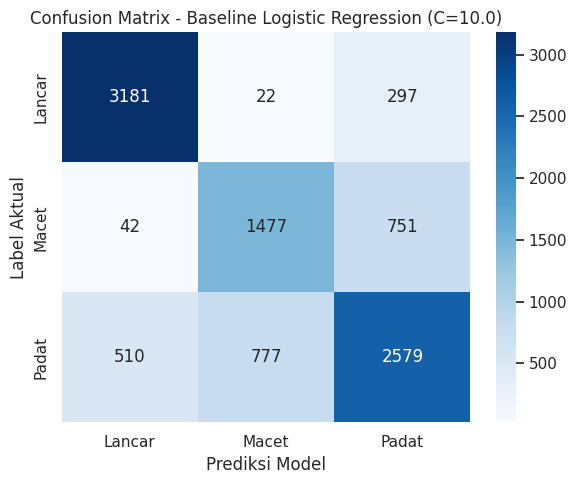

Model baseline tersimpan di ../models/baseline_logreg.joblib


In [4]:
# 3. Pelatihan Model Baseline Terbaik & Evaluasi pada Validation Set
best_c = df_results.loc[df_results["Val F1-Macro"].idxmax(), "C (Regularization)"]
print(f"Best C berdasarkan Validation F1-Macro: {best_c}")

model_baseline = LogisticRegression(C=best_c, solver="lbfgs", max_iter=500, random_state=42)
model_baseline.fit(X_train, y_train)

y_val_pred = model_baseline.predict(X_val)

print("\n=== Classification Report (Validation Set - Baseline) ===")
print(classification_report(y_val, y_val_pred, target_names=class_names))

# Visualisasi Confusion Matrix pada Validation Set
cm = confusion_matrix(y_val, y_val_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title(f"Confusion Matrix - Baseline Logistic Regression (C={best_c})")
plt.xlabel("Prediksi Model")
plt.ylabel("Label Aktual")
plt.tight_layout()
plt.show()

# Simpan model baseline
os.makedirs("../models", exist_ok=True)
joblib.dump(model_baseline, "../models/baseline_logreg.joblib")
print("Model baseline tersimpan di ../models/baseline_logreg.joblib")